In [7]:
# importing the necessary libs
import pandas as pd
import numpy as np
from pathlib import Path

In [8]:
# empty set for docs stats
document_stats = []

In [9]:
# Get the directory where Jupyter is running
current_directory = Path.cwd()

# Move up one level to our project's root directory
project_root = current_directory.parent

In [10]:
# Define the location of our transformed TXT documents
transformed_folder = project_root / "documents" / "transformed"

# Find all transformed TXT documents
txt_files = sorted(transformed_folder.glob("*.txt"))

# Verify our paths
print("Project root:", project_root)
print("Transformed folder:", transformed_folder)
print("Documents found:", len(txt_files))

Project root: /Users/nicolasdilegardia/Desktop/clustering_of_docs
Transformed folder: /Users/nicolasdilegardia/Desktop/clustering_of_docs/documents/transformed
Documents found: 33


In [11]:
# Iterate through all transformed TXT files
for txt_path in sorted(transformed_folder.glob("*.txt")):

    # Read the text from the current document
    text = txt_path.read_text(encoding="utf-8")

    # Calculate document statistics
    word_count = len(text.split())
    character_count = len(text)

    # Store the results
    document_stats.append({
        "filename": txt_path.name,
        "words": word_count,
        "characters": character_count
    })

# Convert our list into a Pandas DataFrame
df = pd.DataFrame(document_stats)

# Display the results
display(df)

,filename,words,characters
0,32624-pdf.txt,178468,1076684
1,Alexander the Great by Jacob Abbott | Project ...,349,2209
2,Ancient China Simplified by Edward Harper Park...,266,1716
3,Ancient Rome: The Lives of Great Men by Mary A...,305,1931
4,pg1.txt,4812,29969
5,pg15663.txt,101297,603886
6,pg18041.txt,17275,104216
7,pg19725.txt,235548,1369822
8,pg20110.txt,153547,888240
9,pg2131.txt,40619,220726


## Inspecting the statistics

In [12]:
# descriptive statistics
print("--Below are the statistics of the documents--\n\n")

display(df[["words", "characters"]].describe())
shortest = df.loc[df["words"].idxmin()]
longest = df.loc[df["words"].idxmax()]

print("\nShortest document:")
print(shortest["filename"], "-", shortest["words"], "words")

print("\nLongest document:")
print(longest["filename"], "-", longest["words"], "words")

--Below are the statistics of the documents--




,words,characters
count,33.000000,3.300000e+01
mean,65451.303030,3.894870e+05
std,52908.444947,3.095849e+05
min,266.000000,1.716000e+03
25%,26886.000000,1.572090e+05
50%,54831.000000,3.280970e+05
75%,89152.000000,5.286210e+05
max,235548.000000,1.369822e+06



Shortest document:
Ancient China Simplified by Edward Harper Parker | Project Gutenberg.txt - 266 words

Longest document:
pg19725.txt - 235548 words


#### Visualizing the distribution

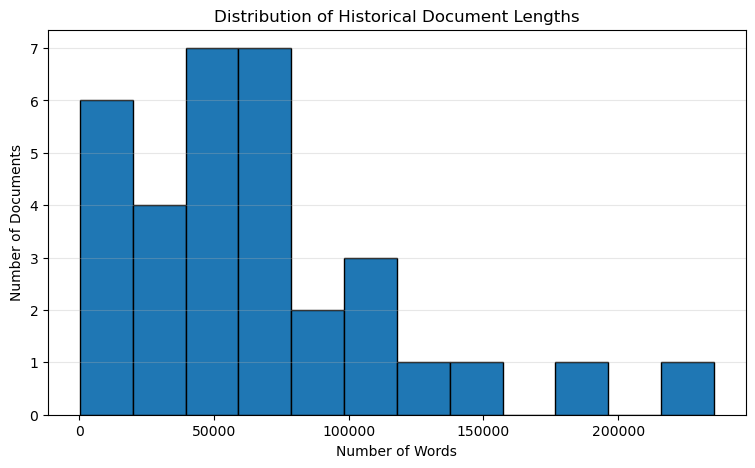

In [13]:
import matplotlib.pyplot as plt

# Create a histogram of document lengths
plt.figure(figsize=(9, 5))

plt.hist(
    df["words"],
    bins=12,
    edgecolor="black"
)

plt.title("Distribution of Historical Document Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Documents")

plt.grid(axis="y", alpha=0.3)
plt.show()

The histogram shows three important characteristics:

1.) Right-skewed distribution: Most documents appear to contain fewer than 80,000 words.

2.) Significant variation: Document lengths range from relatively short texts to books exceeding 200,000 words.

3.) Potential outliers: A small number of exceptionally long documents may influence distance-based clustering.

In [ ]:
# Identify documents containing fewer than 1,000 words
short_documents = df[df["words"] < 1000]

# Display the number of unusually short documents
print("Documents with fewer than 1,000 words:", len(short_documents))

# Display their filenames and word counts
display(short_documents[["filename", "words"]])

# Check whether any documents contain no text
empty_documents = df[df["words"] == 0]

print("Empty documents:", len(empty_documents))